In [1]:
import pickle
import numpy as np
from pathlib import Path

data_dir = Path("data/cifar-100-python")
if not data_dir.exists():
    data_dir = Path("D:/cifar100-project/data/cifar-100-python")
if not data_dir.exists():
    raise FileNotFoundError(f"Dataset folder not found: {data_dir}. Put cifar-100-python inside a data folder next to this notebook, or update data_dir.")

def load_batch(file_path):
    with open(file_path, "rb") as file:
        batch = pickle.load(file, encoding="bytes")

    # Reshape images from flat arrays to 32x32 color images
    images = batch[b"data"].reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    # CIFAR-100 has fine labels for its 100 categories
    labels = np.array(batch[b"fine_labels"])

    return images, labels

x_train, y_train = load_batch(data_dir / "train")
x_test, y_test = load_batch(data_dir / "test")

# Load the 100 class names
with open(data_dir / "meta", "rb") as file:
    meta = pickle.load(file, encoding="bytes")

class_names = [
    name.decode("utf-8") for name in meta[b"fine_label_names"]
]

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)
print("Number of classes:", len(class_names))
print("First class:", class_names[y_train[0]])

Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)
Number of classes: 100
First class: cattle


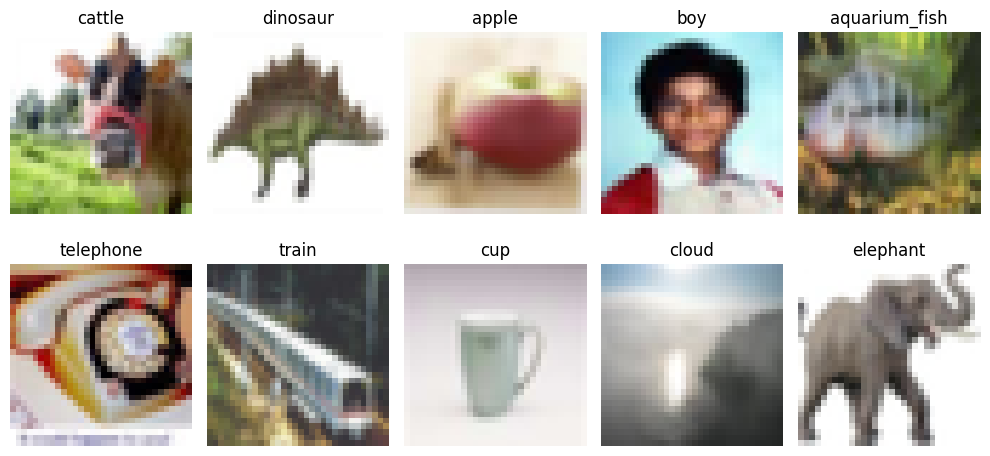

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

# Scale pixel values to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Hold out 10% of training images for validation
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Training: (45000, 32, 32, 3) (45000,)
Validation: (5000, 32, 32, 3) (5000,)
Test: (10000, 32, 32, 3) (10000,)


In [4]:
import time
import tensorflow as tf
from tensorflow.keras import layers, models

# Custom CNN trained from scratch
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(100, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_initial_start = time.perf_counter()
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)
cnn_initial_training_seconds = time.perf_counter() - cnn_initial_start
print(f"Initial CNN training time: {cnn_initial_training_seconds / 60:.2f} minutes")


Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.0406 - loss: 4.3396 - val_accuracy: 0.1662 - val_loss: 3.5215
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.1604 - loss: 3.5255 - val_accuracy: 0.2350 - val_loss: 3.1618
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.2296 - loss: 3.1457 - val_accuracy: 0.2678 - val_loss: 2.9596
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.2729 - loss: 2.8980 - val_accuracy: 0.3140 - val_loss: 2.7636
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.3053 - loss: 2.7218 - val_accuracy: 0.3382 - val_loss: 2.6734
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.3359 - loss: 2.5700 - val_accuracy: 0.3492 - val_loss: 2.5939
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.3714 - loss: 2.3825 - val_accuracy: 0.3646 - val_loss: 2.5233
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.3997 - loss: 2.2426 - 

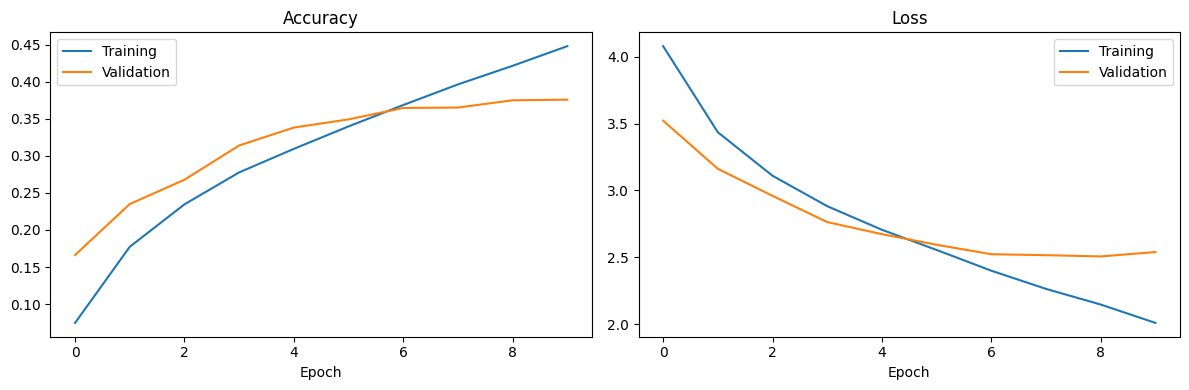

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [6]:
import tensorflow as tf

# Small random changes to training images
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
])

# Augment training data only
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_ds = train_ds.shuffle(10_000).batch(64)
train_ds = train_ds.map(
    lambda images, labels: (augmentation(images, training=True), labels),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

# Keep the current model weights, but use a smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

# Continue training the existing model
cnn_continuation_start = time.perf_counter()
history_more = model.fit(
    train_ds,
    validation_data=(x_val, y_val),
    epochs=30,
    callbacks=callbacks
)
cnn_continuation_seconds = time.perf_counter() - cnn_continuation_start
print(f"CNN continuation time: {cnn_continuation_seconds / 60:.2f} minutes")


Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.3556 - loss: 2.5262 - val_accuracy: 0.3932 - val_loss: 2.3886 - learning_rate: 5.0000e-04
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.3728 - loss: 2.4256 - val_accuracy: 0.3914 - val_loss: 2.4273 - learning_rate: 5.0000e-04
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.3823 - loss: 2.3756 - val_accuracy: 0.3978 - val_loss: 2.3579 - learning_rate: 5.0000e-04
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.3889 - loss: 2.3443 - val_accuracy: 0.4024 - val_loss: 2.3393 - learning_rate: 5.0000e-04
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.3924 - loss: 2.3257 - val_accuracy: 0.4120 - val_loss: 2.3034 - learning_rate: 5.0000e-04
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.4048 - loss: 2.2857 - val_accuracy: 0.4166 - val_loss: 2.2904 - learning_rate: 5.0000e-04
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/ste

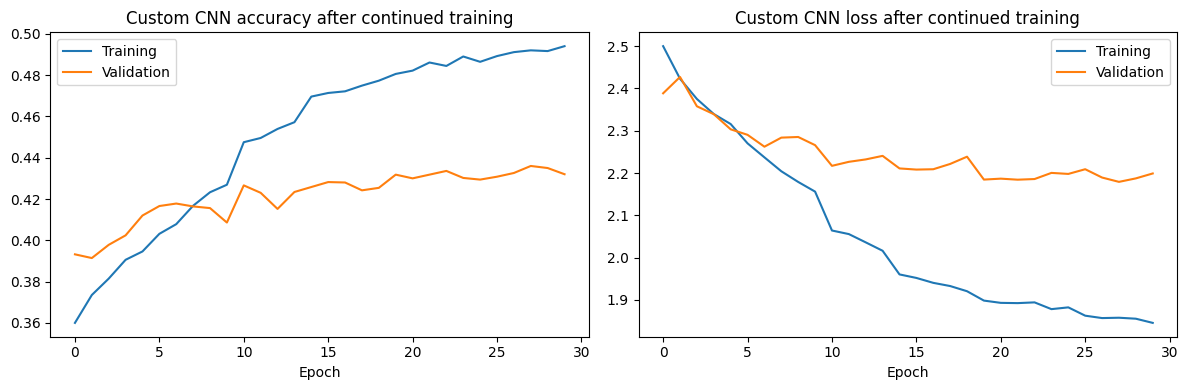

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_more.history["accuracy"], label="Training")
plt.plot(history_more.history["val_accuracy"], label="Validation")
plt.title("Custom CNN accuracy after continued training")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_more.history["loss"], label="Training")
plt.plot(history_more.history["val_loss"], label="Validation")
plt.title("Custom CNN loss after continued training")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()


In [10]:
import time
import tensorflow as tf
from tensorflow.keras import layers, models

# Load MobileNetV2 with its ImageNet-learned image features
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

# First, keep the pre-trained layers frozen
base_model.trainable = False

inputs = layers.Input(shape=(32, 32, 3))

# Mild augmentation during training
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)

# Resize CIFAR-100 images and scale pixels from 0–1 to -1–1
x = layers.Resizing(96, 96)(x)
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

# Extract features using the pre-trained model
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

# CIFAR-100 has 100 output classes
outputs = layers.Dense(100, activation="softmax")(x)

transfer_model = models.Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()

transfer_history = transfer_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

transfer_training_time = time.time() - start_time
print(f"Training time: {transfer_training_time / 60:.2f} minutes")

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 110ms/step - accuracy: 0.2897 - loss: 3.1277 - val_accuracy: 0.6006 - val_loss: 1.4848
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 76s 107ms/step - accuracy: 0.5184 - loss: 1.8071 - val_accuracy: 0.6132 - val_loss: 1.4095
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 76s 108ms/step - accuracy: 0.5623 - loss: 1.6238 - val_accuracy: 0.6200 - val_loss: 1.3933
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 78s 110ms/step - accuracy: 0.5682 - loss: 1.5703 - val_accuracy: 0.6306 - val_loss: 1.3601
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 77s 110ms/step - accuracy: 0.5833 - loss: 1.5205 - val_accuracy: 0.6250 - val_loss: 1.3808
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 77s 110ms/step - accuracy: 0.5892 - loss: 1.4991 - val_accuracy: 0.6214 - val_loss: 1.4002
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 116ms/step - accuracy: 0.5980 - loss: 1.4746 - val_accuracy: 0.6260 - val_loss: 1.4088
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 89s 126ms/step - accuracy: 0.5987 - loss: 1

In [11]:
import tensorflow as tf

# Unfreeze the pre-trained model, then freeze most of its layers
base_model.trainable = True

# Fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Use a very small learning rate so pre-trained features change gradually
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_mobilenetv2_cifar100.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

mobilenet_finetune_start = time.perf_counter()
fine_tune_history = transfer_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=fine_tune_callbacks
)
mobilenet_finetune_seconds = time.perf_counter() - mobilenet_finetune_start
print(f"MobileNetV2 fine-tuning time: {mobilenet_finetune_seconds / 60:.2f} minutes")


Epoch 1/30
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.6271 - loss: 1.3043
Epoch 1: val_accuracy improved from -inf to 0.64820, saving model to best_mobilenetv2_cifar100.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 93s 124ms/step - accuracy: 0.6271 - loss: 1.3042 - val_accuracy: 0.6482 - val_loss: 1.2847 - learning_rate: 1.0000e-05
Epoch 2/30
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.6537 - loss: 1.2057
Epoch 2: val_accuracy improved from 0.64820 to 0.65280, saving model to best_mobilenetv2_cifar100.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 88s 125ms/step - accuracy: 0.6537 - loss: 1.2057 - val_accuracy: 0.6528 - val_loss: 1.2624 - learning_rate: 1.0000e-05
Epoch 3/30
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.6625 - loss: 1.1710
Epoch 3: val_accuracy improved from 0.65280 to 0.66100, saving model to best_mobilenetv2_cifar100.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 89s 127ms/step - accuracy: 0.6625 - loss: 1.1710 - val_accuracy: 0.6610 - val_loss: 1.2564 - learning_

In [12]:
print(f"Best validation accuracy: {max(fine_tune_history.history['val_accuracy']):.2%}")

Best validation accuracy: 69.02%


157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Custom CNN
Accuracy:  44.67%
Precision: 45.00%
Recall:    44.67%
F1-score:  44.18%


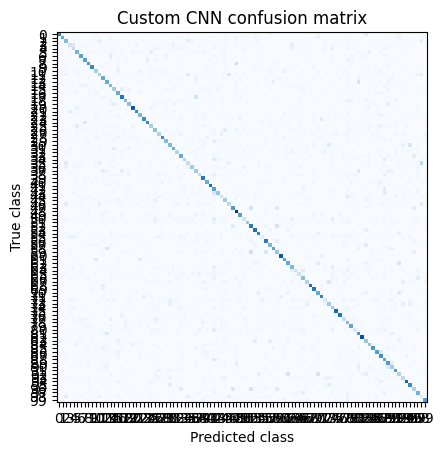

157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step

Fine-tuned MobileNetV2
Accuracy:  68.02%
Precision: 68.37%
Recall:    68.02%
F1-score:  67.84%


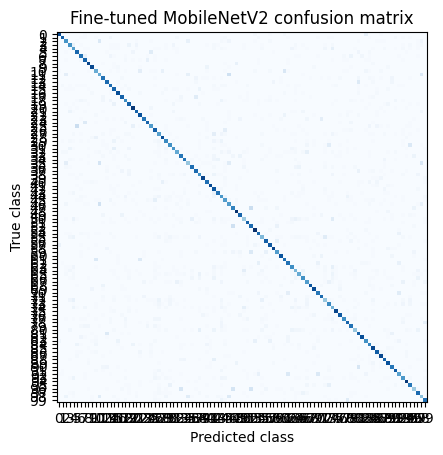

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

def compare_model(model_to_check, model_name):
    probabilities = model_to_check.predict(x_test, batch_size=64)
    predictions = np.argmax(probabilities, axis=1)
    true_labels = y_test.reshape(-1)

    accuracy = accuracy_score(true_labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    print(f"\n{model_name}")
    print(f"Accuracy:  {accuracy:.2%}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall:    {recall:.2%}")
    print(f"F1-score:  {f1:.2%}")

    ConfusionMatrixDisplay.from_predictions(
        true_labels,
        predictions,
        cmap="Blues",
        include_values=False,
        colorbar=False
    )
    plt.title(f"{model_name} confusion matrix")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.show()

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }

cnn_results = compare_model(model, "Custom CNN")
mobilenet_results = compare_model(transfer_model, "Fine-tuned MobileNetV2")

In [14]:
import numpy as np

def show_generalization(name, history):
    best_epoch = np.argmax(history.history["val_accuracy"])
    train_acc = history.history["accuracy"][best_epoch]
    val_acc = history.history["val_accuracy"][best_epoch]

    print(f"{name} — epoch {best_epoch + 1}")
    print(f"Training accuracy:   {train_acc:.2%}")
    print(f"Validation accuracy: {val_acc:.2%}")
    print(f"Gap:                 {train_acc - val_acc:.2%}")

show_generalization("Custom CNN", history_more)
show_generalization("Fine-tuned MobileNetV2", fine_tune_history)

Custom CNN — epoch 28
Training accuracy:   49.20%
Validation accuracy: 43.60%
Gap:                 5.60%
Fine-tuned MobileNetV2 — epoch 22
Training accuracy:   75.02%
Validation accuracy: 69.02%
Gap:                 6.00%


In [15]:
import pandas as pd

# Save the final models for later prediction or app deployment.
model.save("custom_cnn_improved.keras")
transfer_model.save("mobilenetv2_cifar100_finetuned.keras")

cnn_total_training_seconds = cnn_initial_training_seconds + cnn_continuation_seconds
mobilenet_total_training_seconds = transfer_training_time + mobilenet_finetune_seconds

comparison = pd.DataFrame(
    [cnn_results, mobilenet_results],
    index=["Custom CNN", "Fine-tuned MobileNetV2"]
)
comparison["training_time_minutes"] = [
    cnn_total_training_seconds / 60,
    mobilenet_total_training_seconds / 60
]
print(comparison.round(4))


                        accuracy  precision  recall  f1_score  \
Custom CNN                0.4467     0.4500  0.4467    0.4418   
Fine-tuned MobileNetV2    0.6802     0.6837  0.6802    0.6784   

                        training_time_minutes  
Custom CNN                             9.3470  
Fine-tuned MobileNetV2                60.4506  
